In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

# Dataset load
df = pd.read_csv('Mall_Customers.csv')

# Check first 5 rows
print("Data Head:")
print(df.head())

# Check basic info
print("\nDataset Info:")
print(df.info())

Data Head:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [3]:
# We are differentiating customers on basis of Annual Income aur Spending Score
X = df.iloc[:, [3, 4]].values  # Annual Income (col 3) and Spending Score (col 4)

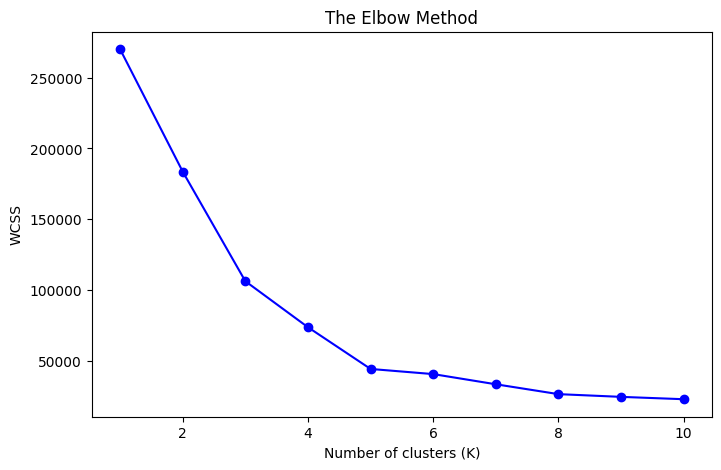

In [4]:
# WCSS (Within-Cluster Sum of Squares) calculate duff diff K values
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS')
plt.show()

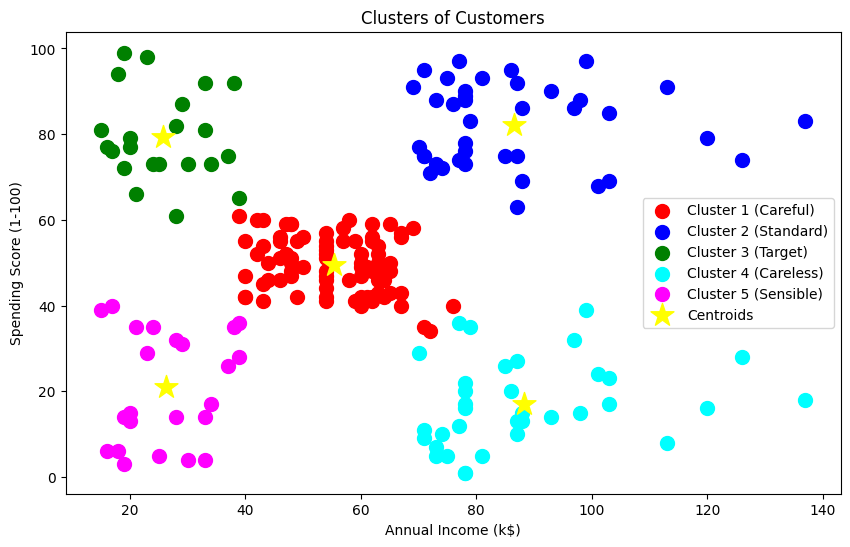

In [5]:
# In the graph where 'Elbow' (mod) is made, that is only optimal K (Usually K = 5)
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X)

# Visualise the Clusters
plt.figure(figsize=(10, 6))
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=100, c='red', label='Cluster 1 (Careful)')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=100, c='blue', label='Cluster 2 (Standard)')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=100, c='green', label='Cluster 3 (Target)')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s=100, c='cyan', label='Cluster 4 (Careless)')
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s=100, c='magenta', label='Cluster 5 (Sensible)')

# Plot the Cluster Centroids
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', marker='*', label='Centroids')

plt.title('Clusters of Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

## 📌 Conclusion & Business Insights

### **Project Summary:**
In this project, we successfully implemented **Unsupervised Machine Learning (K-Means Clustering)** to segment retail/mall customers based on their **Annual Income** and **Spending Score**. Since there were no predefined target labels, an unsupervised learning approach was ideal to discover natural customer groups.

### **Key Steps & Technical Workflow:**
1. **Data Preprocessing & Feature Selection:** Extracted relevant features (Annual Income and Spending Score) to focus on customer purchasing behavior.
2. **Optimal Cluster Selection (Elbow Method):** Utilized the Within-Cluster Sum of Squares (WCSS) metric across multiple $K$ values to determine the optimal number of clusters ($K = 5$).
3. **Model Training & Prediction:** Trained the K-Means Clustering algorithm and assigned each customer to a specific behavioral cluster.
4. **Data Visualization:** Plotted the clusters and their respective centroids using Matplotlib and Seaborn for clear visual interpretation.

### **Business Value & Actionable Insights:**
The K-Means model successfully categorized customers into 5 distinct segments, which can help marketing teams tailor their strategies:
* **Cluster 1 (Careful Customers):** Moderate income, moderate spending. Good target for standard loyalty programs.
* **Cluster 2 (Standard Customers):** Balanced income and spending habits. Reliable base for everyday retail offerings.
* **Cluster 3 (Target / High-Value Customers):** High income and high spending. **(Most Important Group)**: Premium services, exclusive discounts, and VIP memberships should be targeted here.
* **Cluster 4 (Careless Customers):** Low income but high spending. Requires careful credit monitoring or targeted promotions.
* **Cluster 5 (Sensible / Prudent Customers):** High income but low spending. Potential to spend more if targeted with high-value utility products or luxury investments.

---
*Project successfully completed and documented! 🚀*